# Website Traffic Forecasting

Web Sitesi Trafik Tahmini, belirli bir dönemde bir web sitesindeki trafiği tahmin etmek anlamına gelir. Zaman Serisi Tahmininin en iyi kullanım örneklerinden biridir. Bir web sitesindeki trafiği nasıl tahmin edeceğinizi öğreneceğiz.

Web Sitesi Trafik Tahmini için kullandığım veri seti thecleverprogrammer.com'un günlük trafik verilerinden toplanmıştır . Haziran 2021'den Haziran 2022'ye kadar günlük trafik verileri hakkında veri içerir. Veri setini buradan indirebilirsiniz . Şimdi gerekli Python kütüphanelerini ve veri setini içe aktararak web sitesi trafiği tahmin etme görevine başlayalım :

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.arima_model import ARIMA
import statsmodels.api as sm

In [2]:
data = pd.read_csv("Thecleverprogrammer.csv")
print(data.head())

         Date  Views
0  01/06/2021   7831
1  02/06/2021   7798
2  03/06/2021   7401
3  04/06/2021   7054
4  05/06/2021   7973


In [3]:
#Veri kümesi iki sütundan oluşur, tarih ve trafik. İlerlemeden önce, Tarih sütununu Datetime veri türüne dönüştüreceğim

data["Date"] = pd.to_datetime(data["Date"], 
                              format="%d/%m/%Y")
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 391 entries, 0 to 390
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    391 non-null    datetime64[ns]
 1   Views   391 non-null    int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 6.2 KB
None


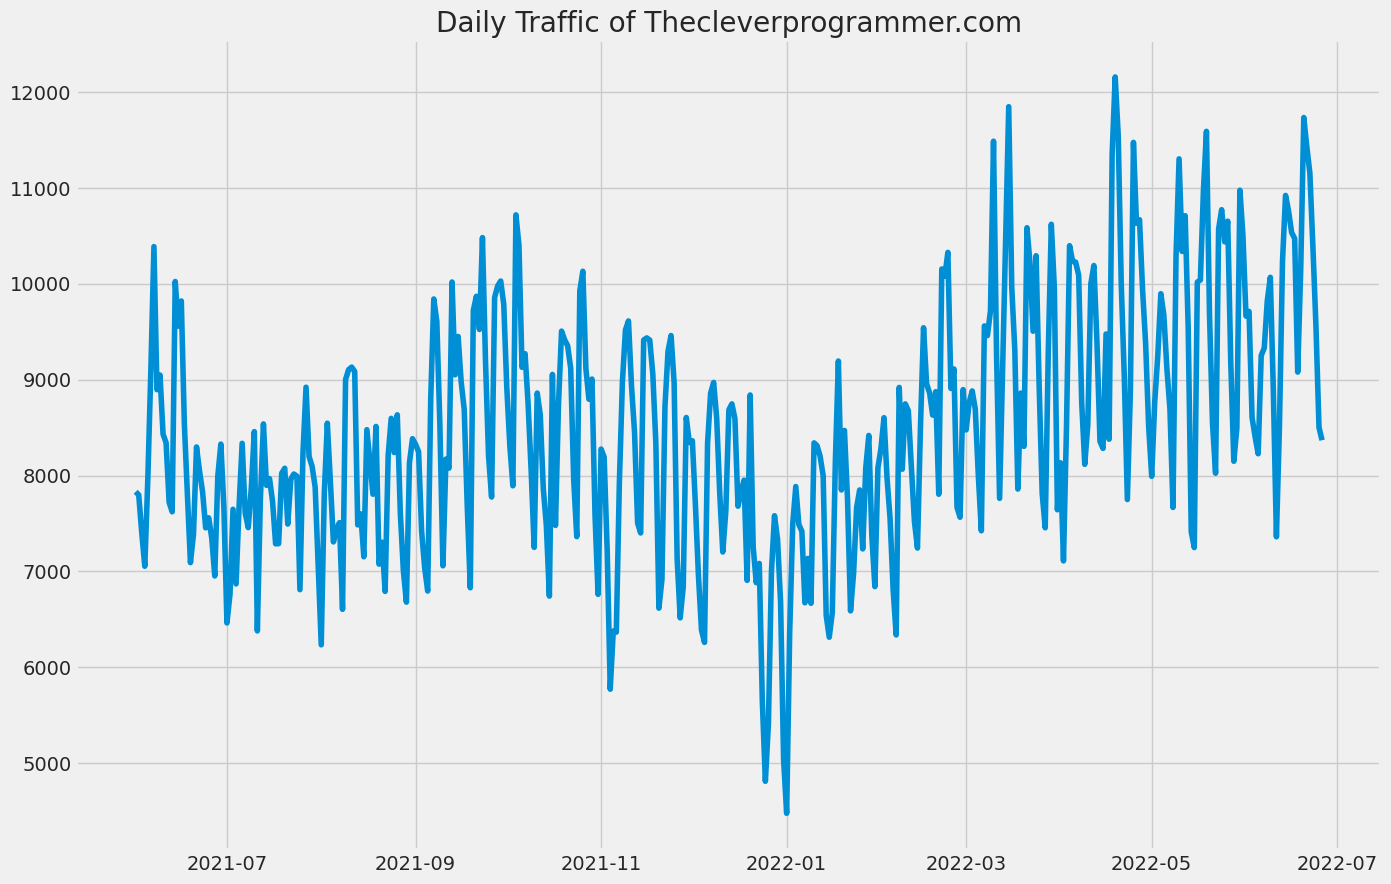

In [4]:
#Date time sütunu başlangıçta bir nesneydi, bu yüzden onu bir Datetime sütununa dönüştürdüm. Şimdi web sitesinin günlük trafiğine bir bakalım

plt.style.use('fivethirtyeight')
plt.figure(figsize=(15, 10))
plt.plot(data["Date"], data["Views"])
plt.title("Daily Traffic of Thecleverprogrammer.com")
plt.show()

Web sitemizin trafik verileri mevsimseldir çünkü web sitesindeki trafik hafta içi artar ve hafta sonu azalır. Zaman Serisi Tahmini problemi üzerinde çalışırken veri setinin mevsimsel olup olmadığını bilmek değerlidir. Aşağıda veri setimizin durağan mı yoksa mevsimsel mi olduğuna nasıl bakabileceğimiz gösterilmektedir

<Figure size 640x480 with 0 Axes>

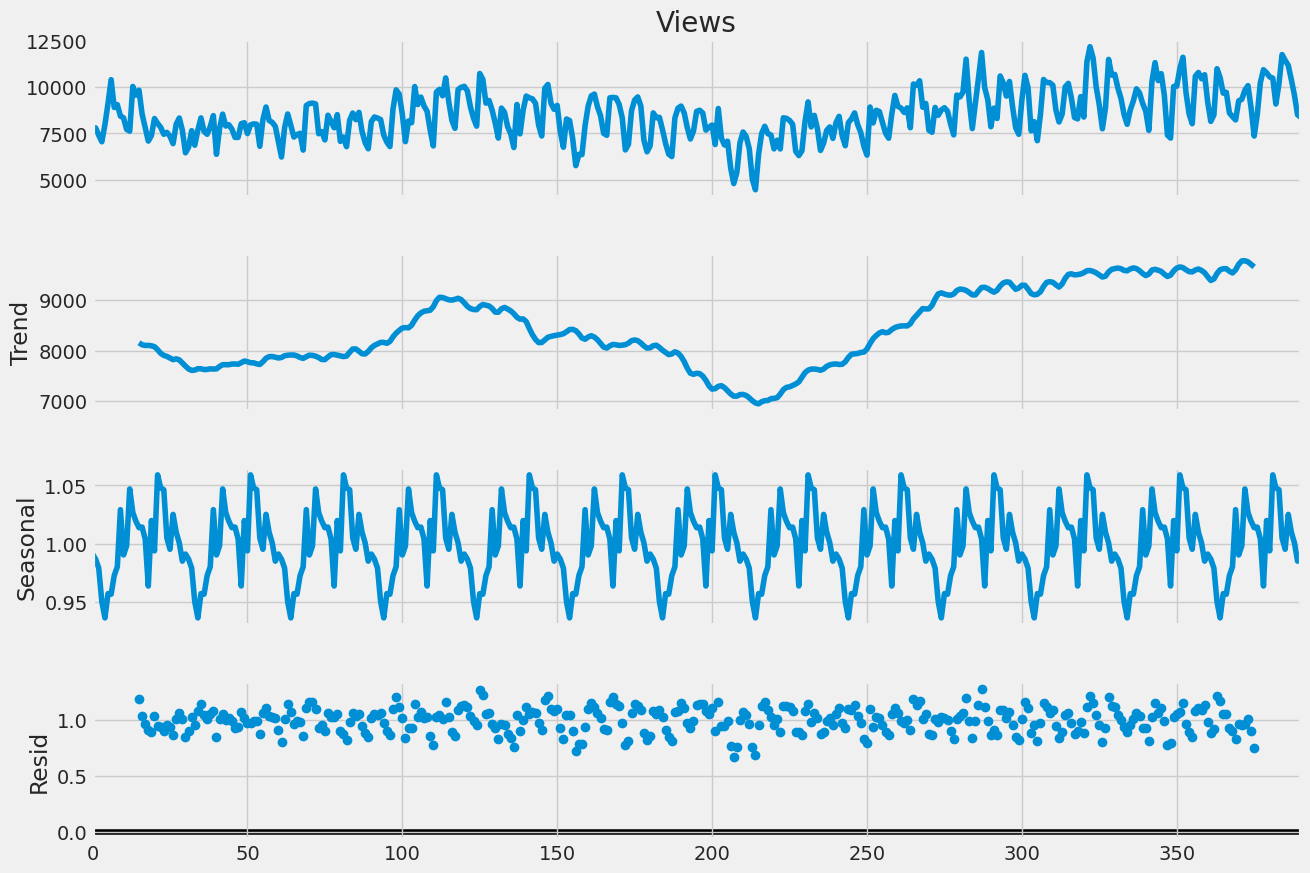

In [8]:
result = seasonal_decompose(data["Views"], 
                            model='multiplicative', 
                            period=30)  # Change 'freq' to 'period'
fig = plt.figure()  
fig = result.plot()  
fig.set_size_inches(15, 10)

In [7]:
#pip install --upgrade statsmodels

<Axes: xlabel='Lag', ylabel='Autocorrelation'>

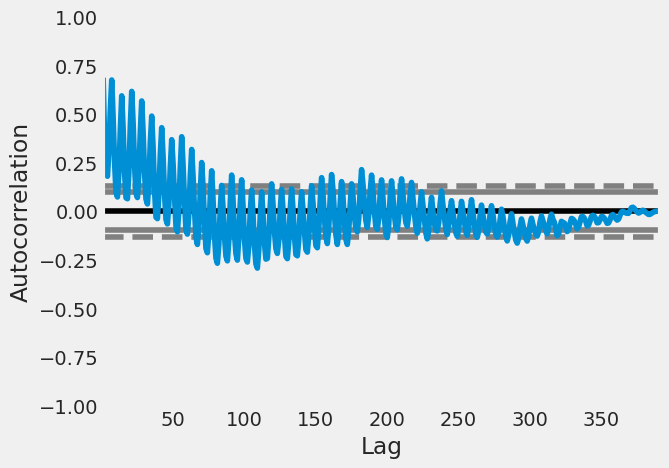

In [9]:
#Web sitesindeki trafiği tahmin etmek için Mevsimsel ARIMA (SARIMA) modelini kullanacağım. SARIMA modelini kullanmadan önce p, d ve q değerlerini bulmak gerekir.

pd.plotting.autocorrelation_plot(data["Views"])

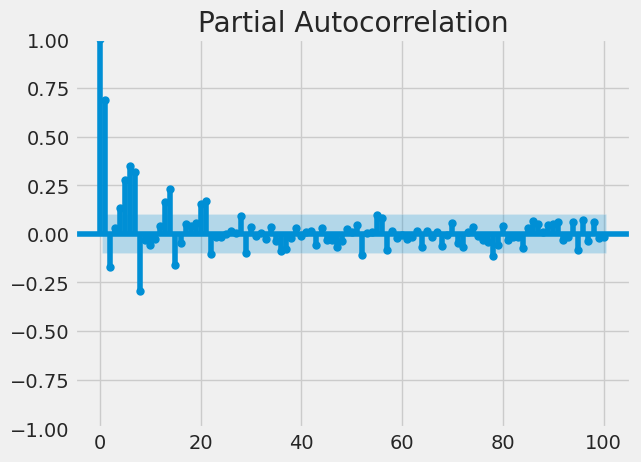

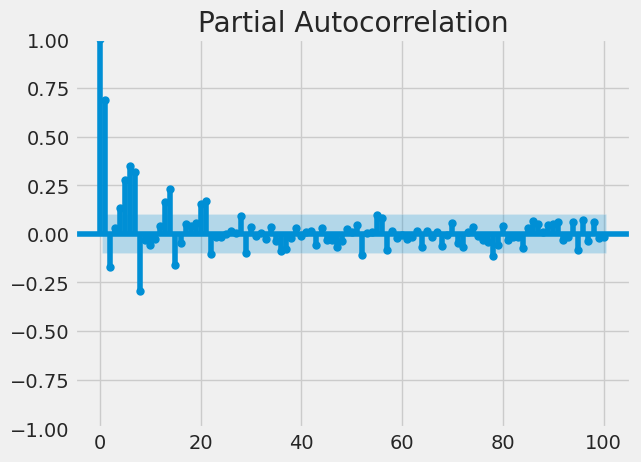

In [10]:
plot_pacf(data["Views"], lags = 100)

In [11]:
#Şimdi, web sitesi trafiğini tahmin etme görevi için bir SARIMA modelini nasıl eğitebileceğimizi görelim

p, d, q = 5, 1, 2
model=sm.tsa.statespace.SARIMAX(data['Views'],
                                order=(p, d, q),
                                seasonal_order=(p, d, q, 12))
model=model.fit()
print(model.summary())

/home/sifa/projects/first/pythonProject/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
 This problem is unconstrained.


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =           15     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  8.26940D+00    |proj g|=  5.28062D-01

At iterate    5    f=  8.06764D+00    |proj g|=  4.51780D-02

At iterate   10    f=  8.01428D+00    |proj g|=  4.59156D-02

At iterate   15    f=  7.98073D+00    |proj g|=  1.14090D-01

At iterate   20    f=  7.96097D+00    |proj g|=  1.73117D-02

At iterate   25    f=  7.95078D+00    |proj g|=  2.22026D-01

At iterate   30    f=  7.94314D+00    |proj g|=  1.85887D-01

At iterate   35    f=  7.93774D+00    |proj g|=  1.40793D-02

At iterate   40    f=  7.93366D+00    |proj g|=  3.10469D-02

At iterate   45    f=  7.93014D+00    |proj g|=  1.58047D-01

At iterate   50    f=  7.92560D+00    |proj g|=  1.49743D-01

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cau

/home/sifa/projects/first/pythonProject/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                                     SARIMAX Results                                      
Dep. Variable:                              Views   No. Observations:                  391
Model:             SARIMAX(5, 1, 2)x(5, 1, 2, 12)   Log Likelihood               -3098.911
Date:                            Sun, 03 Nov 2024   AIC                           6227.821
Time:                                    15:17:17   BIC                           6286.845
Sample:                                         0   HQIC                          6251.247
                                            - 391                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.7601      0.130      5.867      0.000       0.506       1.014
ar.L2         -0.7788      0.135   

In [12]:
#Şimdi web sitesinde önümüzdeki 50 güne ait trafiği tahmin edelim:
predictions = model.predict(len(data), len(data)+50)
print(predictions)


391     9917.925955
392    10805.343259
393    10773.609496
394     9872.845208
395     8810.587293
396     8292.107035
397     8973.325275
398     9733.978660
399    10319.586418
400    10638.284814
401     9878.628642
402     9297.044485
403     8988.840906
404     9093.557256
405    10509.042108
406    10993.393091
407    10912.082012
408    10064.465716
409     9386.867262
410     8603.874218
411     9194.109951
412    10360.076382
413    10621.257593
414    10799.636429
415    10244.702547
416     9380.414712
417     8976.253908
418     9169.415926
419     9925.385734
420    10276.400747
421    10742.554860
422     9880.372887
423     9463.342746
424     8997.405502
425     8875.204702
426    10190.755725
427    10890.504388
428    10921.196667
429    10363.986873
430     9387.877014
431     8691.947800
432     8762.211854
433    10114.388899
434    10571.773388
435    10880.721707
436    10416.965021
437     9268.355269
438     9134.993584
439     9378.931553
440    10338.122450


<Axes: >

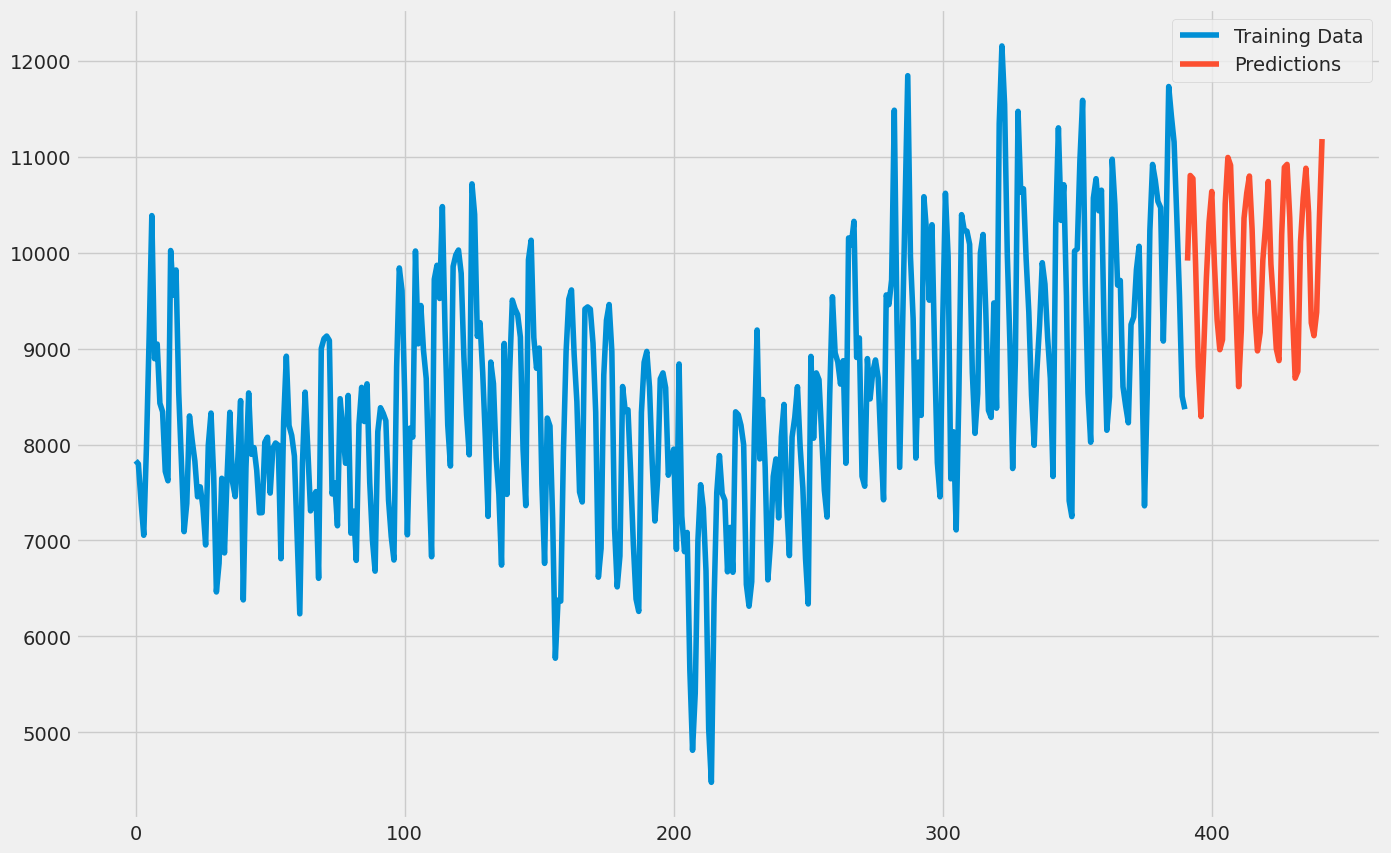

In [13]:
#Tahminleri şu şekilde çizebiliriz
data["Views"].plot(legend=True, label="Training Data", 
                   figsize=(15, 10))
predictions.plot(legend=True, label="Predictions")

Yani belirli bir dönem için web sitesi trafiğini bu şekilde tahmin edebilirsiniz. Web sitesi trafiği tahmini, özgeçmişinizde bahsedebileceğiniz en iyi veri bilimi proje fikirlerinden biridir.

In [14]:
import joblib
import statsmodels.api as sm

# Fit your model
p, d, q = 5, 1, 2
model = sm.tsa.statespace.SARIMAX(data['Views'],
                                   order=(p, d, q),
                                   seasonal_order=(p, d, q, 12))
model = model.fit()

# Save the model
joblib.dump(model, 'sarimax_model.pkl')

/home/sifa/projects/first/pythonProject/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =           15     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  8.26940D+00    |proj g|=  5.28062D-01


 This problem is unconstrained.



At iterate    5    f=  8.06764D+00    |proj g|=  4.51780D-02

At iterate   10    f=  8.01428D+00    |proj g|=  4.59156D-02

At iterate   15    f=  7.98073D+00    |proj g|=  1.14090D-01

At iterate   20    f=  7.96097D+00    |proj g|=  1.73117D-02

At iterate   25    f=  7.95078D+00    |proj g|=  2.22026D-01

At iterate   30    f=  7.94314D+00    |proj g|=  1.85887D-01

At iterate   35    f=  7.93774D+00    |proj g|=  1.40793D-02

At iterate   40    f=  7.93366D+00    |proj g|=  3.10469D-02

At iterate   45    f=  7.93014D+00    |proj g|=  1.58047D-01

At iterate   50    f=  7.92560D+00    |proj g|=  1.49743D-01

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tn

/home/sifa/projects/first/pythonProject/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


['sarimax_model.pkl']